# Pandas Practice: The Iris Dataset

In [2]:
# --- Starter code: run this cell first ---
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../../data/iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


## Part 1: Exploring the Data

### Challenge 1: Preview and inspect

Display the first 5 rows and the last 10 rows of the DataFrame.

In [3]:
# First 5 rows
display(df.head())

# Last 10 rows
display(df.tail(10))

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


,sepal_length,sepal_width,petal_length,petal_width,species
140,6.7,3.1,5.6,2.4,Iris-virginica
141,6.9,3.1,5.1,2.3,Iris-virginica
142,5.8,2.7,5.1,1.9,Iris-virginica
143,6.8,3.2,5.9,2.3,Iris-virginica
144,6.7,3.3,5.7,2.5,Iris-virginica
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


**Explanation**

head() shows the first 5 rows and tail(10) the last 10; display() lets both DataFrames render in one cell instead of only the last expression.


### Challenge 2: How many irises are in the dataset?

How many rows and columns does the DataFrame have?

In [4]:
# .shape returns a (rows, columns) tuple
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 150
Columns: 5


**Explanation**

df.shape is a (rows, columns) tuple, so shape[0] is the row count and shape[1] is the column count. You could also read both from df.info().


### Challenge 3: How many species are there?

Find out how many distinct species exist in the dataset, and what they are called.

In [5]:
# Number of distinct species
print("Number of species:", df["species"].nunique())

# The species names themselves
print("Species:", df["species"].unique())

Number of species: 3
Species: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str


**Explanation**

nunique() counts the distinct species and unique() lists them. value_counts() would also work and additionally show how many rows fall in each species.


---

## Part 2: Statistics

### Challenge 4: Descriptive statistics for petal length

Calculate the mean, median, and mode for `petal_length`. What can you conclude about the distribution?

In [6]:
# .mode() returns a Series because a column can have more than one most-frequent value
print("Mean:", df["petal_length"].mean())
print("Median:", df["petal_length"].median())
print("Mode:", df["petal_length"].mode()[0])

Mean: 3.758666666666666
Median: 4.35
Mode: 1.5


**Explanation**

mean, median, and mode summarise the centre of petal_length. mode() returns a Series (a column can tie for most frequent), so we take the first element with [0]. Here mean and median differ noticeably, hinting the distribution is not symmetric.


### Challenge 5: Range and spread

What is the smallest and largest value for `petal_length`? Calculate the variance and standard deviation.

In [7]:
print("Min:", df["petal_length"].min())
print("Max:", df["petal_length"].max())
print("Variance:", df["petal_length"].var())
print("Standard deviation:", df["petal_length"].std())

Min: 1.0
Max: 6.9
Variance: 3.113179418344519
Standard deviation: 1.7644204199522626


**Explanation**

min and max give the range while var and std measure spread; std is just the square root of var and is in the same unit (cm) as the data, which makes it easier to interpret.


### Challenge 6: Full summary

Use a single command to get the basic descriptive statistics for all columns.

In [8]:
# .describe() gives count, mean, std, min, quartiles, and max for every numeric column
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


**Explanation**

describe() returns count, mean, std, min, the three quartiles, and max for every numeric column in one table, so it is the quickest way to get a full statistical overview.


### Challenge 7: Overall average sepal length

What is the average `sepal_length` across all 150 flowers?

In [9]:
print("Average sepal length:", df["sepal_length"].mean())

Average sepal length: 5.843333333333334


**Explanation**

mean() on the sepal_length column averages across all 150 flowers. Selecting the single column first keeps the result a single number rather than a row of means.


---

## Part 3: Groupby

### Challenge 8: Count by species

Use `groupby` to count the number of observations for each species.

In [10]:
# Group by species, then count rows in each group
df.groupby("species").size()

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
dtype: int64

**Explanation**

groupby('species').size() counts the rows in each group. value_counts() on the species column would give the same numbers; size() is the natural groupby way to do it.


### Challenge 9: Average measurements by species

Use `groupby` to find the average `sepal_length`, `sepal_width`, `petal_length`, and `petal_width` for each species.

In [11]:
# Group by species, then take the mean of every numeric column
df.groupby("species")[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
].mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
Iris-setosa,5.006,3.418,1.464,0.244
Iris-versicolor,5.936,2.770,4.260,1.326
Iris-virginica,6.588,2.974,5.552,2.026


**Explanation**

grouping by species and calling mean() on the four measurement columns produces one average per species per column. We list the columns explicitly so non-numeric columns are not pulled in.


---

## Part 4: Column Operations and Filtering

### Challenge 10: Add a new column

Create a new column `sepal_total` that is the sum of `sepal_width` and `sepal_length`.

In [12]:
# Adding two columns elementwise creates a new Series we assign back as a column
df["sepal_total"] = df["sepal_width"] + df["sepal_length"]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,sepal_total
0,5.1,3.5,1.4,0.2,Iris-setosa,8.6
1,4.9,3.0,1.4,0.2,Iris-setosa,7.9
2,4.7,3.2,1.3,0.2,Iris-setosa,7.9
3,4.6,3.1,1.5,0.2,Iris-setosa,7.7
4,5.0,3.6,1.4,0.2,Iris-setosa,8.6


**Explanation**

assigning df['sepal_total'] = df['sepal_width'] + df['sepal_length'] adds the two columns elementwise (row by row) and stores the result as a new column. The new column appears at the right edge of the DataFrame.


### Challenge 11: Add petal area

Create a new column `petal_area` as a rough estimate of petal area: `petal_length × petal_width`.

In [13]:
# Rough petal area estimate: length times width
df["petal_area"] = df["petal_length"] * df["petal_width"]
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,sepal_total,petal_area
0,5.1,3.5,1.4,0.2,Iris-setosa,8.6,0.28
1,4.9,3.0,1.4,0.2,Iris-setosa,7.9,0.28
2,4.7,3.2,1.3,0.2,Iris-setosa,7.9,0.26
3,4.6,3.1,1.5,0.2,Iris-setosa,7.7,0.30
4,5.0,3.6,1.4,0.2,Iris-setosa,8.6,0.28


**Explanation**

multiplying petal_length by petal_width row by row gives a rough rectangular area estimate, saved as petal_area. It is only an approximation since a petal is not a perfect rectangle.


### Challenge 12: Filter by petal area

Create a new DataFrame containing only the flowers where `petal_area` is greater than 1 cm².

In [14]:
# Boolean mask keeps only the rows where the condition is True
large_petals = df[df["petal_area"] > 1]
large_petals.head()

,sepal_length,sepal_width,petal_length,petal_width,species,sepal_total,petal_area
50,7.0,3.2,4.7,1.4,Iris-versicolor,10.2,6.58
51,6.4,3.2,4.5,1.5,Iris-versicolor,9.6,6.75
52,6.9,3.1,4.9,1.5,Iris-versicolor,10.0,7.35
53,5.5,2.3,4.0,1.3,Iris-versicolor,7.8,5.20
54,6.5,2.8,4.6,1.5,Iris-versicolor,9.3,6.90


**Explanation**

df[df['petal_area'] > 1] uses a boolean mask: the inner comparison makes a True/False Series and indexing with it keeps only the True rows. The original df is unchanged because the result is a new DataFrame.


### Challenge 13: Split by species

Create three separate DataFrames, one for each species, using the full dataset.

In [15]:
# One filtered DataFrame per species
setosa = df[df["species"] == "Iris-setosa"]
versicolor = df[df["species"] == "Iris-versicolor"]
virginica = df[df["species"] == "Iris-virginica"]

print("Setosa rows:", len(setosa))
print("Versicolor rows:", len(versicolor))
print("Virginica rows:", len(virginica))

Setosa rows: 50
Versicolor rows: 50
Virginica rows: 50


**Explanation**

each line filters the full dataset for one species name, giving three independent DataFrames. The row counts confirm the classic 50 per species split of the Iris data.


---

## Part 5: Visualisation

### Challenge 14: Histogram of petal length

Create a histogram of `petal_length`. Describe the distribution, is it symmetric, skewed, or does it appear to have multiple peaks?

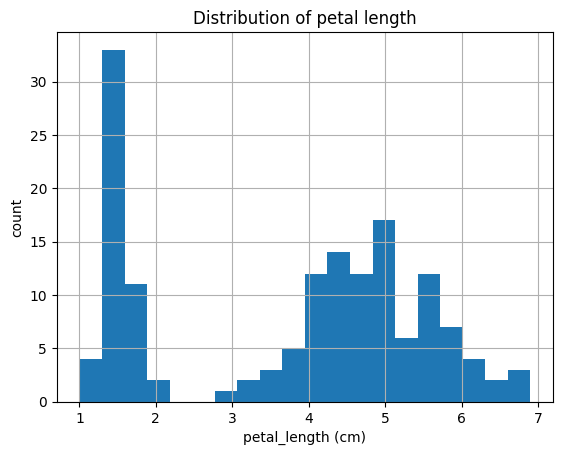

In [16]:
df["petal_length"].hist(bins=20)
plt.xlabel("petal_length (cm)")
plt.ylabel("count")
plt.title("Distribution of petal length")
plt.show()

# The distribution is bimodal: one cluster of short petals (Iris-setosa)
# is clearly separated from a second, broader cluster of longer petals
# (versicolor and virginica), so it is not symmetric.

**Explanation**

hist() bins petal_length into bars showing how often each range occurs. The two separated clusters reveal a bimodal, non-symmetric shape: setosa has very short petals while the other two species have longer ones.


### Challenge 15: Scatter matrix of petal dimensions

Create a scatter plot of `petal_length` vs `petal_width`. Do larger petals tend to be longer as well?

> Bonus: use `pd.plotting.scatter_matrix(df)` to see all pairwise relationships at once.

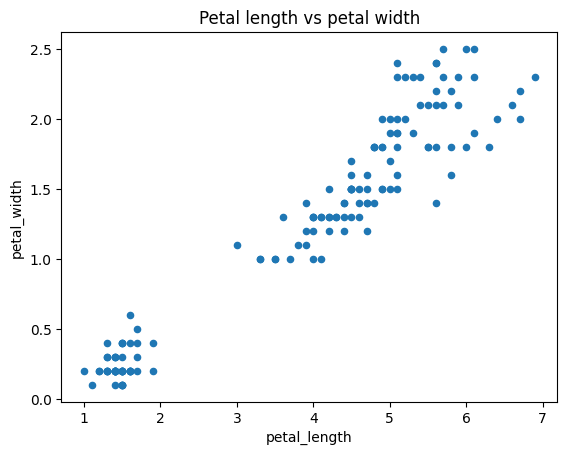

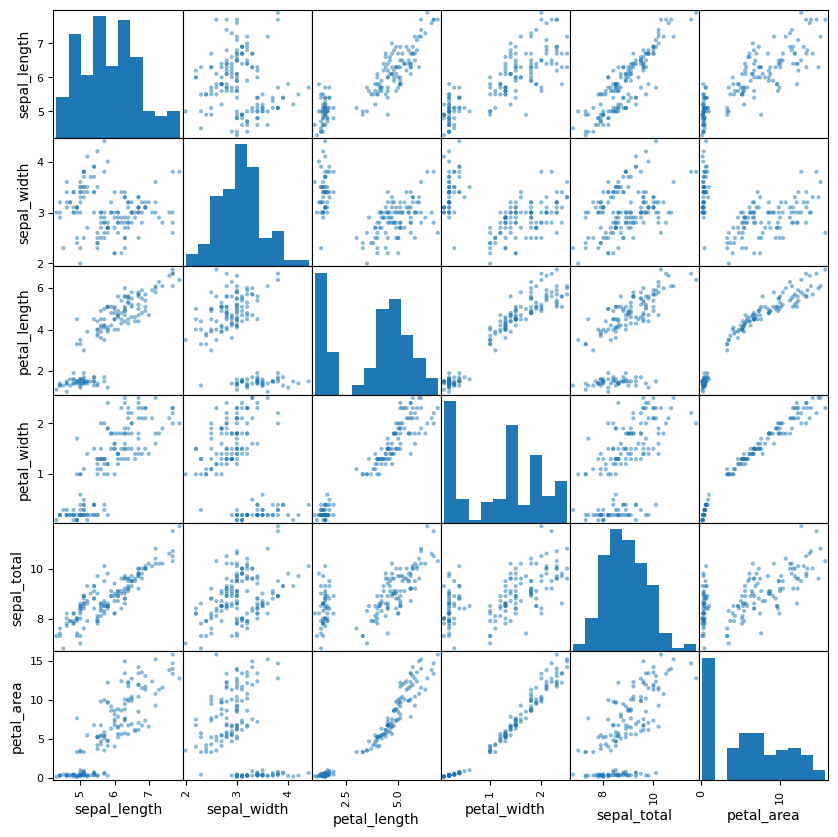

In [17]:
df.plot.scatter(x="petal_length", y="petal_width")
plt.title("Petal length vs petal width")
plt.show()

# Yes: the points trend upward, so longer petals tend to be wider too.

# Bonus: all pairwise relationships at once
pd.plotting.scatter_matrix(df, figsize=(10, 10))
plt.show()

**Explanation**

the scatter plot of petal_length against petal_width shows an upward trend, so longer petals tend to be wider too (a positive relationship). The bonus scatter_matrix draws every pairwise plot at once for a quick overview of all correlations.
